In [1]:
from astropy.io import fits
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, AsinhStretch
import numpy as np
from vis import plot_model_residual, plot_data_psf
import numpy as np
from scipy.ndimage import map_coordinates, zoom
from inspect_target import data_info
from plot_flux import plot_flux_slice

## Case 1: Filter = F356W

In [2]:
## here my science cutout is at 0.05”/pix, while the PSF you want to use is on 0.063”/pixel.

data = fits.open("../data/RUBIES-BLAGN-1/F115W.fits")
psf = fits.open("../PSF_files/J0100-2017/F115W.fits")


#print(psf[1].header.get("PIXELSCL"))
print(data[0].header.get("CD1_1"))             # pixel_scale = abs(-1.3888889e-05) * 3600 ≈ 0.05 arcsec/pixel

-1.3888888888888e-05


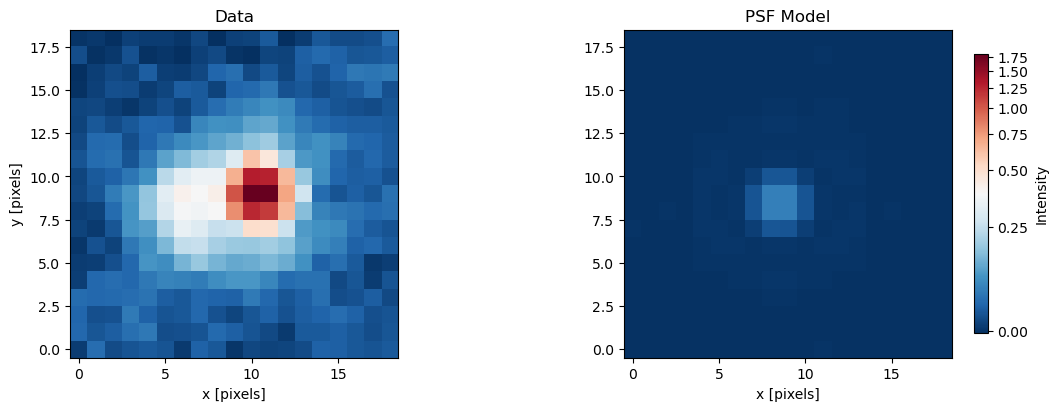

In [3]:
data = fits.getdata("../data/J0100-2017/F356W.fits")
psf = fits.getdata("../PSF_files/J0100-2017/F356W.fits")

plot_data_psf(data[91:110,91:110], psf[91:110,91:110], psf_title="PSF Model", cmap="RdBu_r")

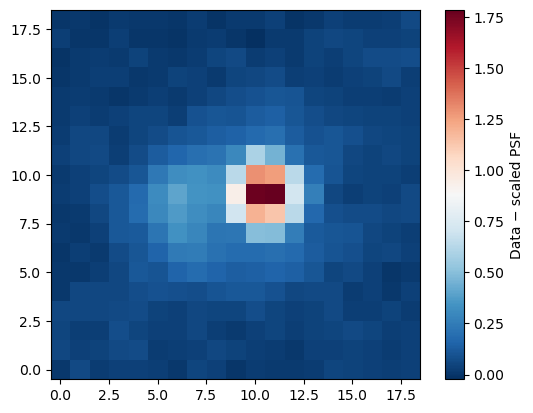

In [4]:

## data - psf

residual = data - psf 

v = np.nanmax(np.abs(residual))
plt.imshow(residual[91:110,91:110], origin="lower", cmap="RdBu_r")
plt.colorbar(label="Data − scaled PSF")
plt.show()

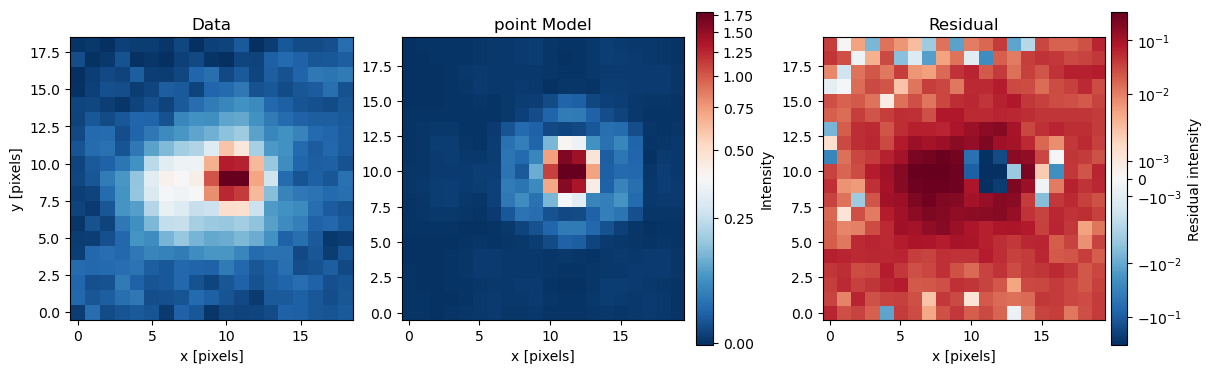

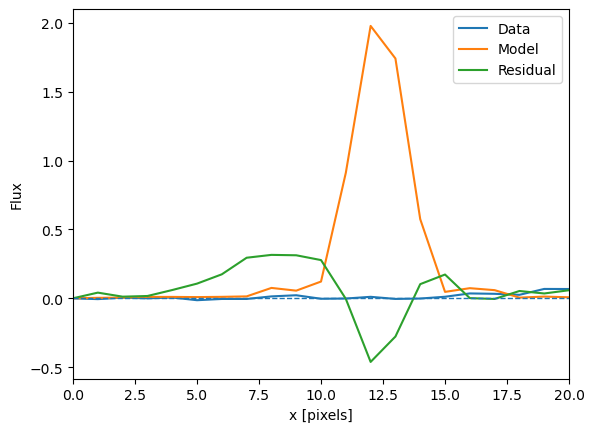

In [5]:
## psf with point+exp
data = fits.getdata("../data/J0100-2017/F356W.fits")
model = fits.getdata("../imfit_models/J0100-2017/F356W_point.fits")
residual = fits.getdata("../imfit_resid/J0100-2017/F356W_point.fits")

plot_model_residual(data[91:110,91:110], model, residual, model_title="point Model", cmap="RdBu_r")
plot_flux_slice(data, model, residual, 9.5, 0, 20)

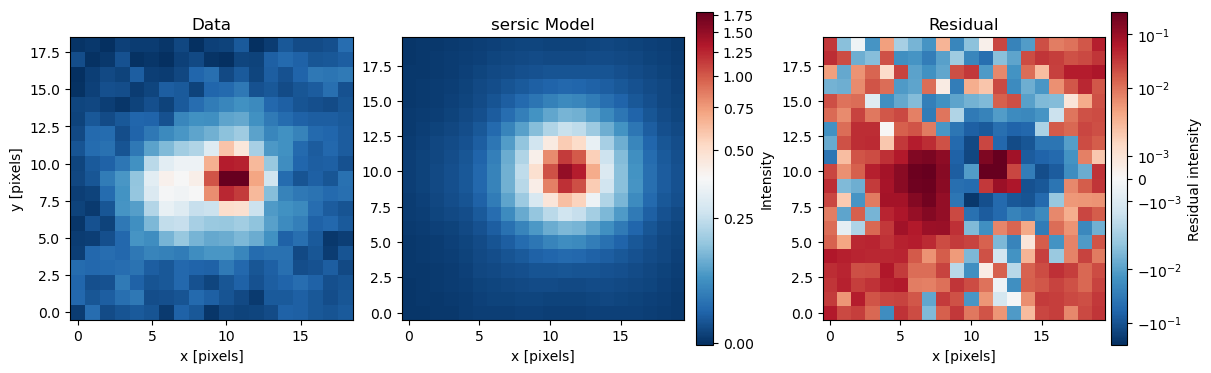

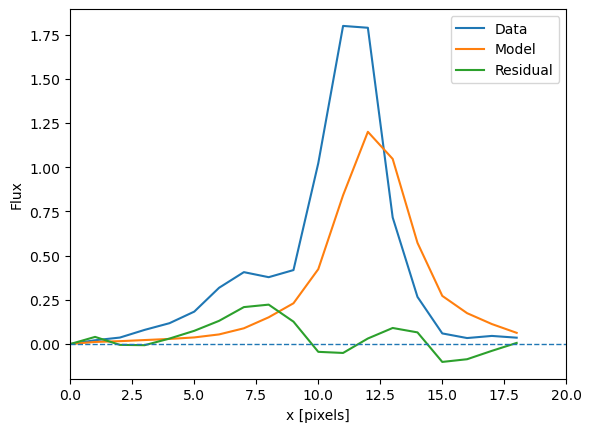

In [6]:
## psf with point+exp
data = fits.getdata("../data/J0100-2017/F356W.fits")
model = fits.getdata("../imfit_models/J0100-2017/F356W_sersic.fits")
residual = fits.getdata("../imfit_resid/J0100-2017/F356W_sersic.fits")

plot_model_residual(data[91:110,91:110], model, residual, model_title="sersic Model", cmap="RdBu_r")
plot_flux_slice(data[91:110,91:110], model, residual, 9, 0, 20)

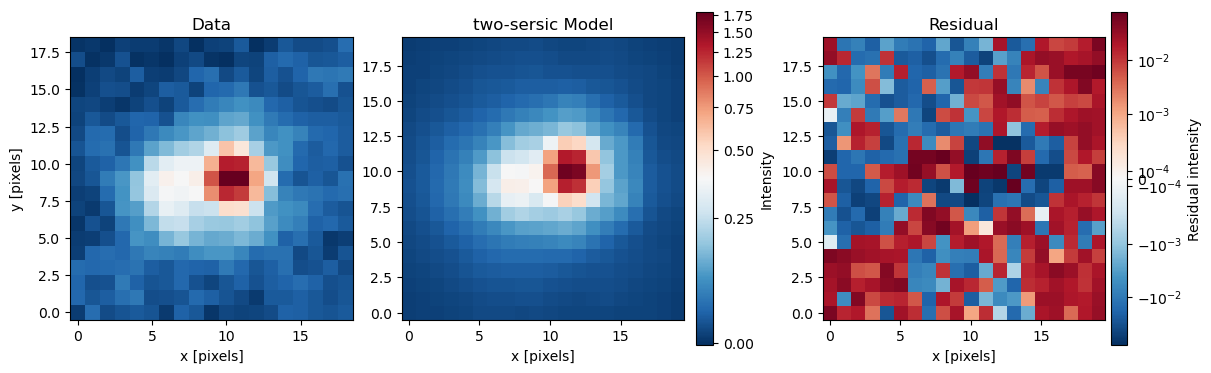

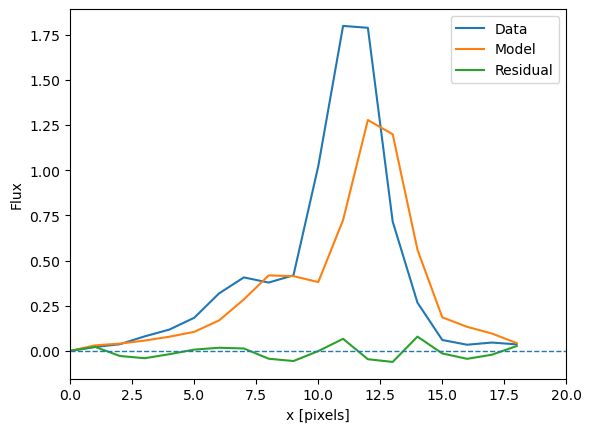

In [7]:
## two sersic profiles

## psf with point+exp
data = fits.getdata("../data/J0100-2017/F356W.fits")
model = fits.getdata("../imfit_models/J0100-2017/F356W_2sersic.fits")
residual = fits.getdata("../imfit_resid/J0100-2017/F356W_2sersic.fits")

plot_model_residual(data[91:110,91:110], model, residual, model_title="two-sersic Model", cmap="RdBu_r")
plot_flux_slice(data[91:110,91:110], model, residual, 9, 0, 20)

## Case 1: Filter = F115W

In [8]:
## here my science cutout is at 0.05”/pix, while the PSF you want to use is on 0.063”/pixel.

data = fits.open("../data/J0100-2017/F115W.fits")
psf = fits.open("../PSF_files/J0100-2017/F115W.fits")


#print(psf[1].header.get("PIXELSCL"))
print(data[0].header.get("CD1_1"))             # pixel_scale = abs(-1.3888889e-05) * 3600 ≈ 0.05 arcsec/pixel
data_info('../data/J0100-2017/F115W.fits')

-1.3888888888888e-05
File: ../data/J0100-2017/F115W.fits
Shape: (200, 200)
Min: -0.12983274459838867
Max: 278.755615234375
Sky median: -0.004680003970861435
Sky RMS: 0.047732915654885515
Peak numpy x,y: 197 57
Suggested imfit X0,Y0: 198 58


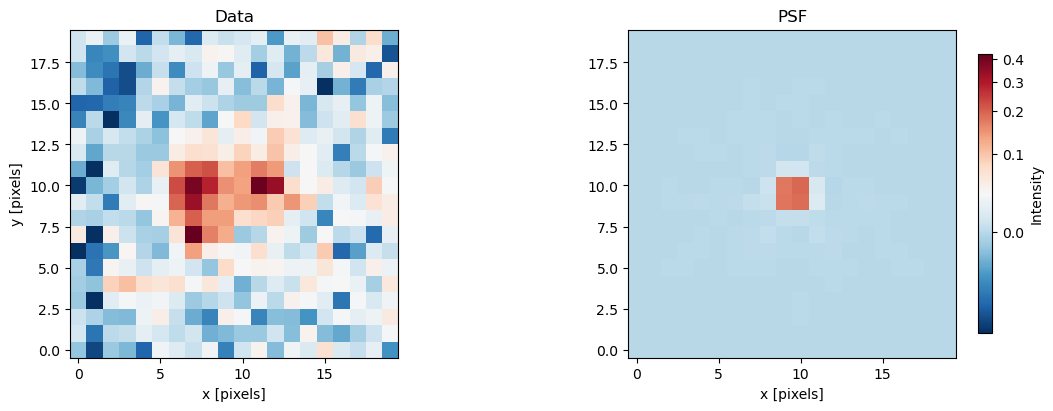

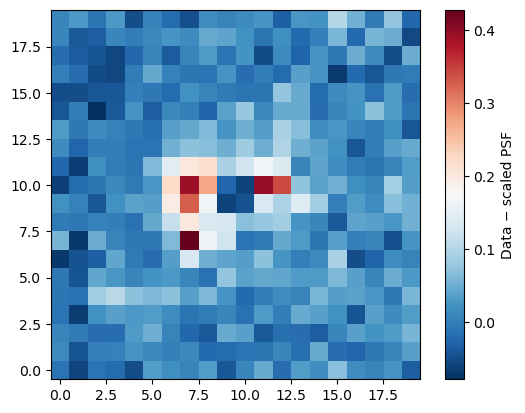

In [9]:
data = fits.getdata("../data/J0100-2017/F115W.fits")
psf = fits.getdata("../PSF_files/J0100-2017/F115W.fits")
plot_data_psf(data[90:110, 90:110], psf[90:110, 90:110], cmap="RdBu_r")

residual = data - psf 
v = np.nanmax(np.abs(residual))
plt.imshow(residual[90:110, 90:110], origin="lower", cmap="RdBu_r")
plt.colorbar(label="Data − scaled PSF")
plt.show()

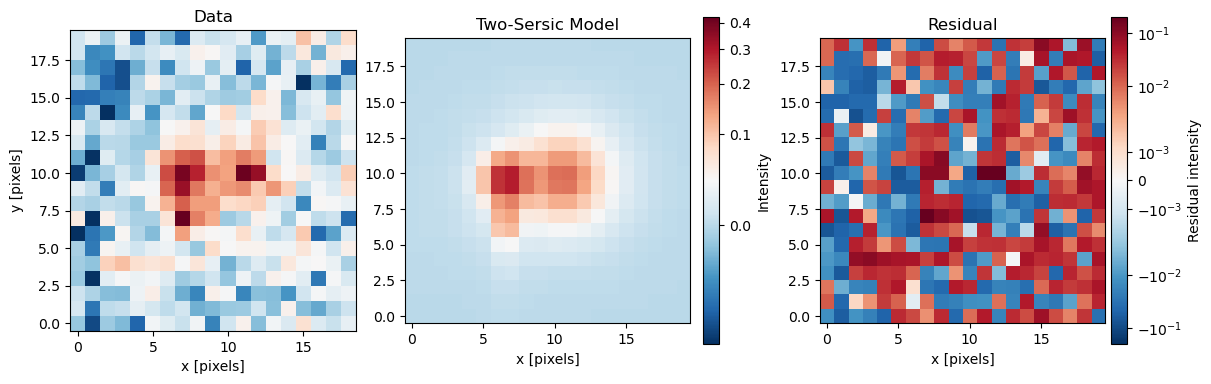

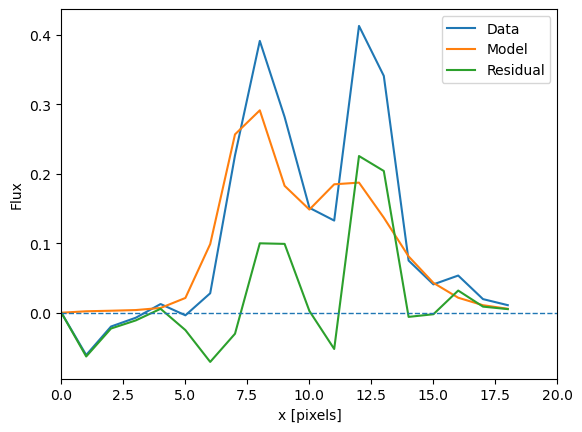

In [11]:
##trying 2 sersic
data = fits.getdata("../data/J0100-2017/F115W.fits")
model = fits.getdata("../imfit_models/J0100-2017/F115W_3sersic.fits")
residual = fits.getdata("../imfit_resid/J0100-2017/F115W_3sersic.fits")

plot_model_residual(data[90:110, 90:109], model, residual, model_title="Two-Sersic Model", cmap="RdBu_r")
plot_flux_slice(data[90:110, 90:109], model, residual, 10, 0, 20)